## PARTE II - Parcial corte I

La Dirección de Bienestar Universitario afirma que “el promedio de horas de estudio
semanal de los estudiantes de la universidad es de 16 horas”.\
Usted ha sido contratado como analista de datos para verificar esta afirmación usando
evidencia estadística. Para ello trabajará con un conjunto de datos simulado que usted mismo
generará.

Datos a simular:\
Número de observaciones: n = 200.\
Variable principal: horas_estudio (horas de estudio semanales).\
Distribución base: Normal.\
Media sugerida: entre 13 y 17 horas.\
Desviación estándar sugerida: entre 3 y 6 horas.\
Semilla: su fecha de nacimiento en formato YYYYMMDD.\
Asegure que no haya valores negativos (las horas deben ser ≥ 0).

In [6]:
# Importamos las librerías necesarias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [7]:
# Creacion del dataset segun espesificaciones del parcial

np.random.seed(19970822) # Fijar semilla usando fecha de nacimiento

n = 200
mu_sim = 15     # entre 13 y 17
sd_sim = 4      # entre 3 y 6

horas = np.random.normal(loc=mu_sim, scale=sd_sim, size=n)
horas = np.clip(horas, 0, None)   # sin valores negativos

df = pd.DataFrame({"horas_estudio": horas})
df.head(10)

,horas_estudio
0,11.882341
1,18.845095
2,9.939129
3,16.577210
4,21.846688
5,18.908610
6,8.497771
7,8.466579
8,11.840878
9,22.457414


¿por qué es importante fijar una semilla?\
La semilla garantiza la reproducibilidad del experimento.\
Esto significa que cualquier persona que ejecute exactamente el   
mismo código con la misma semilla obtendrá los mismos resultados

¿Qué significa simular datos bajo una distribución normal?
Significa generar observaciones artificiales que se comportan como una variable real que sigue la campana de Gauss

In [8]:
# Estadistica descriptiva

x = df["horas_estudio"]

n      = len(x)
media  = x.mean()
mediana= x.median()
sd     = x.std(ddof=1)
minimo = x.min()
maximo = x.max()

print("n:", n)
print("Media:", round(media,4))
print("Mediana:", round(mediana,4))
print("Desv. estándar:", round(sd,4))
print("Mínimo:", round(minimo,4))
print("Máximo:", round(maximo,4))

n: 200
Media: 15.1252
Mediana: 15.2228
Desv. estándar: 3.9067
Mínimo: 5.0705
Máximo: 25.2533


Interpretacion: en promedio los estudiantes dedican unas 15.2 horas semanales al estudio;\
la mediana casi idéntica indica simetría. La desviación de 3.9 horas muestra dispersión moderada:\
lo habitual es estudiar entre ~10.7 y ~18.9 horas. El mínimo (5.07) y el máximo (25.25)\
reflejan casos extremos de muy poca y mucha dedicación.

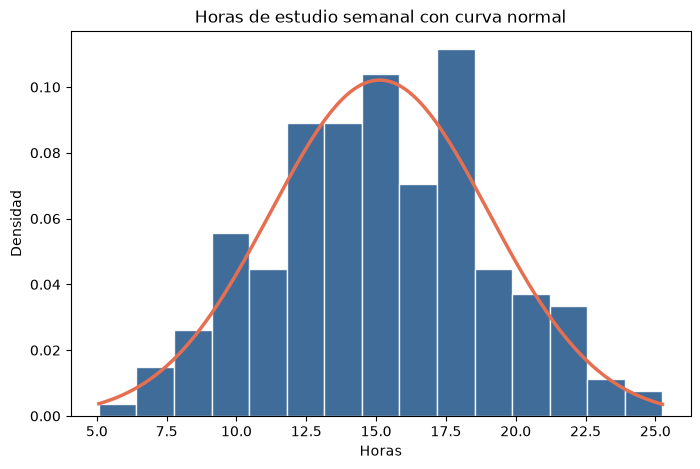

In [ ]:
# Histograma con curva normal

plt.figure(figsize=(8,5))

plt.hist(
    x, bins=15, 
    density=True, 
    color="#2b5c8f", 
    edgecolor="white",
    alpha=0.9
)

eje = np.linspace(
    x.min(), 
    x.max(), 
    200
)

plt.plot(
    eje, 
    stats.norm.pdf(
        eje, 
        media, 
        sd
    ), 
    color="#e76f51", 
    linewidth=2.5
)

plt.title("Horas de estudio semanal con curva normal")
plt.xlabel("Horas"); plt.ylabel("Densidad")
plt.show()

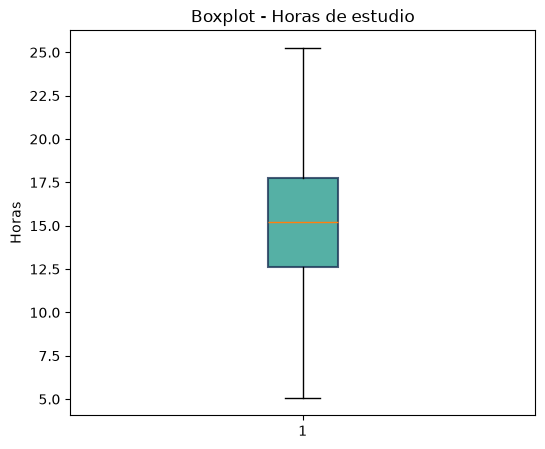

In [22]:
# Boxplot

plt.figure(figsize=(6,5))

plt.boxplot(
    x, 
    patch_artist=True,
    boxprops=dict(
        facecolor="#2a9d8f",
        color="#1d3557",
        linewidth=1.5,
        alpha=0.8
    )
)

plt.title("Boxplot - Horas de estudio")
plt.ylabel("Horas")
plt.show()

¿qué se observa?\
Histograma: los datos se agrupan en forma de campana alrededor de las 15 horas, con la mayoría de estudiantes entre 12.5\
y 18 horas semanales. La curva normal se ajusta bien a las barras; las pequeñas irregularidades son propias del azar de la simulación.

Boxplot: La mediana está cerca de 15.2 horas y queda casi en el centro de la caja (entre 12.6 y 17.7 horas).\
Los bigotes van de unas 5 a 25 horas y son de largo parecido.

¿La distribución parece simétrica?\
Sí. La caja está centrada, los bigotes son similares y el histograma no muestra una cola más larga que la otra.

¿Se identifican valores atípicos?\
No. El boxplot no marca ningún punto fuera de los bigotes, así que todas las observaciones están dentro del rango esperado.

In [ ]:
# Regla empírica

for k in [1,2,3]:
    li = media - k*sd
    ls = media + k*sd
    pct = ((x >= li) & (x <= ls)).mean()*100
    print(f"x̄ ± {k}s = [{li:.3f}, {ls:.3f}] -> {pct:.2f}%")

x̄ ± 1s = [11.218, 19.032] -> 67.00%
x̄ ± 2s = [7.312, 22.939] -> 95.50%
x̄ ± 3s = [3.405, 26.845] -> 100.00%


Los porcentajes quedaron muy cerca de lo esperado. Las pequeñas diferencias se explican\
porque trabajamos con 200 datos y no con toda la población. En el tercer intervalo dio 100%\
simplemente porque ningún estudiante se alejó tanto del promedio.

In [ ]:
# Estandarización y puntaje Z

df["z"] = (x - media) / sd

print("Media de Z:", round(df["z"].mean(),6))
print("Desv. de Z:", round(df["z"].std(ddof=1),6))

print("\n|Z| > 2:")
print(df.loc[df["z"].abs() > 2, ["horas_estudio","z"]].round(3))

print("\n|Z| > 3:")
print(df.loc[df["z"].abs() > 3, ["horas_estudio","z"]].round(3))

Media de Z: -0.0
Desv. de Z: 1.0

|Z| > 2:
     horas_estudio      z
25          23.369  2.110
26          23.110  2.044
43           6.610 -2.180
74          25.253  2.592
130         23.160  2.057
144          7.260 -2.013
146          5.071 -2.574
151         25.212  2.582
198          7.045 -2.068

|Z| > 3:
Empty DataFrame
Columns: [horas_estudio, z]
Index: []


In [ ]:
# Puntaje Z

z_horas = (22 - media) / sd
z_acad  = (4.3 - 3.5) / 0.35

print("Z estudiante 22 horas:", round(z_horas,4))
print("Z estudiante promedio 4.3:", round(z_acad,4))

Z estudiante 22 horas: 1.7598
Z estudiante promedio 4.3: 2.2857


Al estandarizar, la media queda en 0 y la desviación en 1, tal como debe ser.

Hay 9 estudiantes con |Z| mayor a 2: 5.07, 6.61, 7.05, 7.26, 23.11, 23.16, 23.37, 25.21 y 25.25 horas.\
Son quienes estudian mucho menos o mucho más que el resto. Ninguno supera |Z| = 3, así que no hay casos extremos.

En la comparación, el estudiante que estudia 22 horas tiene Z = 1.76 y el del promedio 4.3 tiene Z = 2.29.\
Destaca más el segundo, porque se aleja más del promedio de su propio grupo.

In [17]:
p20    = stats.norm.cdf(20, media, sd)
p10_18 = stats.norm.cdf(18, media, sd) - stats.norm.cdf(10, media, sd)

print("P(X <= 20):", round(p20*100,2), "%")
print("P(10 <= X <= 18):", round(p10_18*100,2), "%")

P(X <= 20): 89.4 %
P(10 <= X <= 18): 67.43 %


Según el modelo, el 89.4% estudia 20 horas o menos y el 67.4% estudia entre 10 y 18 horas.

In [23]:
# Intervalo de confianza

gl = n - 1
error_estandar = sd / np.sqrt(n)
t_critico = stats.t.ppf(0.975, gl)
margen = t_critico * error_estandar

li = media - margen
ls = media + margen

print("Grados de libertad:", gl)
print("Error estándar:", round(error_estandar,5))
print("t crítico:", round(t_critico,5))
print("Margen de error:", round(margen,5))
print("IC 95%: [", round(li,4), ",", round(ls,4), "]")
print("¿16 está dentro?", li <= 16 <= ls)

Grados de libertad: 199
Error estándar: 0.27625
t crítico: 1.97196
Margen de error: 0.54474
IC 95%: [ 14.5804 , 15.6699 ]
¿16 está dentro? False


¿El valor de 16 horas (afirmado por Bienestar Universitario) está contenido\
dentro del intervalo? ¿Qué implica esto?

Las 16 horas que afirma Bienestar Universitario quedan fuera del intervalo. Esto indica que su\
afirmación no coincide con lo que muestran los datos. La lectura correcta del intervalo es que, si\
repitiéramos el muestreo muchas veces, cerca del 95% de los intervalos construidos contendría el\
promedio real de la población.

In [ ]:
# Prueba de hipótesis

mu0 = 16
t_calc = (media - mu0) / error_estandar
p_valor = 2 * stats.t.sf(abs(t_calc), gl)

print("t calculado:", round(t_calc,4))
print("p-valor:", p_valor)
print("Decisión:", "Se rechaza H0" if p_valor < 0.05 else "No se rechaza H0")

print(stats.ttest_1samp(x, 16))

t calculado: -3.1669
p-valor: 0.0017834635610326623
Decisión: Se rechaza H0
TtestResult(statistic=np.float64(-3.1668633828932355), pvalue=np.float64(0.0017834635610326623), df=np.int64(199))


In [21]:
n2 = 20
ee2 = sd / np.sqrt(n2)
tc2 = stats.t.ppf(0.975, n2-1)

print("IC n=20: [", round(media - tc2*ee2,4), ",", round(media + tc2*ee2,4), "]")
t2 = (media - mu0)/ee2
print("t:", round(t2,4), "p:", 2*stats.t.sf(abs(t2), n2-1))

IC n=20: [ 13.2968 , 16.9536 ]
t: -1.0015 p: 0.32919358631362483


El estadístico dio t = -3.1669 y el p-valor 0.00178, así que con α = 0.05 se rechaza H₀. La función stats.ttest_1samp(x, 16) arroja lo mismo,\
lo que confirma el cálculo manual.

Lo que esto significa: si el promedio real fuera de 16 horas, sería muy raro obtener una muestra con un promedio de 15.13. Por eso concluimos\
que el promedio verdadero es distinto de 16.

Los dos métodos coinciden, y siempre lo hacen: el 16 quedó fuera del intervalo y la prueba lo rechazó.

Si la muestra fuera de 20 estudiantes, el intervalo sería [13.297, 16.954], mucho más amplio y ahora sí incluiría el 16. El estadístico\
bajaría a t = -1.0015 con p = 0.329, o sea que ya no se rechazaría H₀. Con menos datos hay más incertidumbre y la evidencia se vuelve más\
débil. El riesgo al interpretar mal el p-valor es creer que mide la probabilidad de que H₀ sea cierta, cuando en realidad solo indica qué\
tan compatibles son los datos con esa hipótesis.